# Thử nghiệm nhiều giá trị K cho phân cụm khách hàng

Notebook này dùng dữ liệu khách hàng định danh trong PostgreSQL DWH để thử nhiều số cụm `K` cho K-Means trên các biến RFM. Notebook phục vụ khám phá và so sánh mô hình; mục 4 ghi kết quả mới nhất vào bảng riêng `public.kmeans_k_experiment_results` để Superset có thể trực quan hóa, không thay đổi các bảng DWH hay pipeline chính.

## Cách chạy
1. Cài các thư viện trong `requirements.txt` và chọn kernel Python của dự án trong VS Code.
2. Khởi động PostgreSQL và chạy ETL chính để nạp DWH.
3. Mở notebook này, chạy lần lượt các cell từ trên xuống.
4. Điều chỉnh `K_MIN` và `K_MAX` ở cell cấu hình để thử thêm/bớt số cụm.

Notebook dùng cùng cấu hình kết nối DWH như `dwh_connection.py` (`DWH_DATABASE_URL` hoặc các biến `PG*`). Silhouette score lớn hơn thường thể hiện cụm tách biệt hơn; Elbow/inertia cần được xem kết hợp với khả năng diễn giải nghiệp vụ.

In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sqlalchemy import text

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "dwh_connection.py").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "dwh_connection.py").exists():
    raise FileNotFoundError("Không tìm thấy dwh_connection.py. Hãy mở notebook từ thư mục notebooks hoặc thư mục gốc dự án.")

sys.path.insert(0, str(PROJECT_ROOT))
from dwh_connection import get_engine

print(f"Project root: {PROJECT_ROOT}")

## 1. Nạp giao dịch của khách định danh

Khách vãng lai bị loại khỏi phân tích RFM vì nhiều giao dịch không định danh đang được gom vào cùng một mã guest.

In [4]:
from pathlib import Path
import sys

import pandas as pd
from sqlalchemy import text

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "dwh_connection.py").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "dwh_connection.py").exists():
    raise FileNotFoundError("Không tìm thấy dwh_connection.py trong thư mục hiện tại hoặc thư mục cha.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from dwh_connection import get_engine

query = text("""
    SELECT
        c.CustomerID AS "CustomerID",
        c.CustomerCode AS "CustomerCode",
        c.Country AS "Country",
        f.InvoiceNo AS "InvoiceNo",
        f.InvoiceTimestamp AS "InvoiceTimestamp",
        f.TotalRevenue AS "TotalRevenue"
    FROM Fact_Sales AS f
    JOIN Dim_Customer AS c ON f.CustomerKey = c.CustomerKey
    WHERE c.IsGuestCustomer = 0
""")

engine = get_engine()
with engine.connect() as connection:
    sales = pd.read_sql_query(query, connection)

if sales.empty:
    raise ValueError("Không có giao dịch khách định danh. Hãy kiểm tra ETL và dữ liệu trong PostgreSQL DWH.")

sales["InvoiceTimestamp"] = pd.to_datetime(sales["InvoiceTimestamp"], errors="raise")
print(f"Số dòng giao dịch: {len(sales):,}")
print(f"Số khách định danh: {sales['CustomerID'].nunique():,}")
sales.head()

Số dòng giao dịch: 392,688
Số khách định danh: 4,338


,CustomerID,CustomerCode,Country,InvoiceNo,InvoiceTimestamp,TotalRevenue
0,17850,CUST-17850,United Kingdom,536365,2010-12-01 08:26:00,15.30
1,17850,CUST-17850,United Kingdom,536365,2010-12-01 08:26:00,20.34
2,17850,CUST-17850,United Kingdom,536365,2010-12-01 08:26:00,22.00
3,17850,CUST-17850,United Kingdom,536365,2010-12-01 08:26:00,20.34
4,17850,CUST-17850,United Kingdom,536365,2010-12-01 08:26:00,20.34


## 2. Tính các biến RFM

- **Recency:** số ngày từ giao dịch cuối cùng của khách đến ngày mốc phân tích.
- **Frequency:** số hóa đơn khác nhau.
- **Monetary:** tổng doanh thu của khách.

Ngày mốc được xác định giống script khai phá chính: thời điểm giao dịch mới nhất cộng một ngày.

In [5]:
snapshot_date = sales["InvoiceTimestamp"].max() + pd.Timedelta(days=1)

rfm = (
    sales.groupby("CustomerID", as_index=False)
    .agg(
        CustomerCode=("CustomerCode", "first"),
        Country=("Country", "first"),
        LastPurchaseDate=("InvoiceTimestamp", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalRevenue", "sum"),
    )
)
rfm["Recency"] = (snapshot_date - rfm["LastPurchaseDate"]).dt.days
rfm["Monetary"] = rfm["Monetary"].round(2)

print(f"Ngày mốc phân tích: {snapshot_date}")
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

Ngày mốc phân tích: 2011-12-10 12:50:00


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


## 3. Chuẩn hóa đặc trưng và cấu hình K

Các biến RFM thường lệch phải, vì vậy notebook dùng `log1p`; sau đó chuẩn hóa bằng `StandardScaler`, tương tự pipeline khai phá chính. Có thể chỉnh khoảng K bên dưới.

In [7]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

K_MIN = 2
K_MAX = 10
RANDOM_STATE = 42
N_INIT = 10

if K_MIN < 2:
    raise ValueError("K_MIN phải từ 2 trở lên để tính Silhouette score.")
if K_MAX < K_MIN:
    raise ValueError("K_MAX phải lớn hơn hoặc bằng K_MIN.")
if len(rfm) <= K_MIN:
    raise ValueError("Cần nhiều khách hàng hơn K_MIN để phân cụm.")

k_max_effective = min(K_MAX, len(rfm) - 1)
if k_max_effective < K_MAX:
    print(f"Giảm K_MAX xuống {k_max_effective} vì số khách hàng hiện có là {len(rfm)}.")

rfm_log = pd.DataFrame({
    "Recency": np.log1p(rfm["Recency"]),
    "Frequency": np.log1p(rfm["Frequency"]),
    "Monetary": np.log1p(rfm["Monetary"].clip(lower=0)),
})
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
k_values = list(range(K_MIN, k_max_effective + 1))

print(f"Thử các K: {k_values}")
print(f"Số khách hàng đưa vào phân cụm: {len(rfm):,}")

Thử các K: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Số khách hàng đưa vào phân cụm: 4,338


## 4. Chạy K-Means cho từng K và so sánh

`Inertia` (WCSS) luôn giảm hoặc giữ nguyên khi tăng K; dùng biểu đồ Elbow để quan sát điểm mức giảm bắt đầu chậm lại. `Silhouette` đánh giá độ gắn kết trong cụm và độ tách biệt giữa các cụm. Chọn K không nên dựa vào một chỉ số duy nhất.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from dwh_connection import get_engine

results = []
models = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    models[k] = model
    results.append({"K": k, "Inertia_WCSS": model.inertia_, "Silhouette": score})

results_df = pd.DataFrame(results).sort_values("K").reset_index(drop=True)
display(results_df.style.format({"Inertia_WCSS": "{:,.2f}", "Silhouette": "{:.4f}"}))

best_k = int(results_df.loc[results_df["Silhouette"].idxmax(), "K"])
results_df["Is_Best_K"] = results_df["K"].eq(best_k)

engine = get_engine()
results_df.to_sql(
    name="kmeans_k_experiment_results",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False,
)

print(f"K có Silhouette cao nhất trong khoảng thử nghiệm: {best_k}")
print("Đã ghi kết quả mới nhất vào public.kmeans_k_experiment_results để Superset sử dụng.")

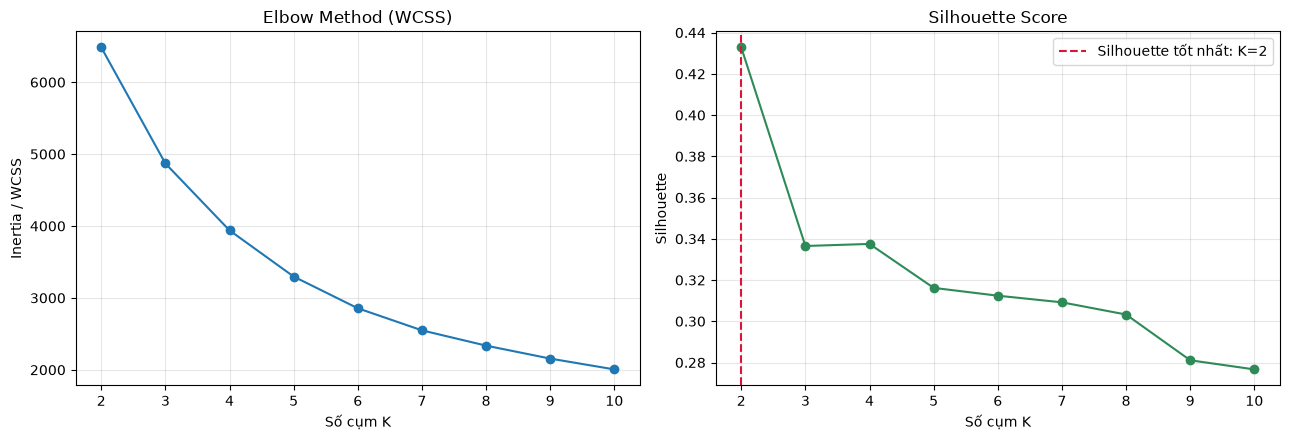

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results_df["K"], results_df["Inertia_WCSS"], marker="o")
axes[0].set_title("Elbow Method (WCSS)")
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Inertia / WCSS")
axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df["K"], results_df["Silhouette"], marker="o", color="seagreen")
axes[1].axvline(best_k, color="crimson", linestyle="--", label=f"Silhouette tốt nhất: K={best_k}")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("Silhouette")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Xem đặc điểm các cụm tại K được chọn

Bảng dưới đây mô tả số khách, Recency, Frequency và Monetary trung bình theo cụm. Nhãn cụm K-Means chỉ là số hiệu; số hiệu không tự mang ý nghĩa tốt/xấu. Hãy xem các chỉ số RFM để diễn giải.

In [11]:
rfm_result = rfm.copy()
rfm_result["KMeans_Cluster"] = models[best_k].labels_

cluster_summary = (
    rfm_result.groupby("KMeans_Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        TotalMonetary=("Monetary", "sum"),
    )
    .round(2)
    .sort_values("AvgMonetary", ascending=False)
)
display(cluster_summary)

print("Ghi chú: notebook chỉ hiển thị kết quả thử nghiệm; không ghi CSV hay thay đổi script production.")

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary
KMeans_Cluster,,,,,
1,1666,25.89,8.44,4539.60,7562979.20
0,2672,134.09,1.67,495.59,1324229.69


Ghi chú: notebook chỉ hiển thị kết quả thử nghiệm; không ghi CSV hay thay đổi script production.
